# Checkpoint 1

## Data Source

Dataset: Lahman Baseball Database (Society for American Baseball Research — SABR)
https://sabr.org/lahman-database/

This dataset contains historical MLB statistics from 1871 through 2025.
Specifically, we will be looking at the following statistics:
* Team Performance ([Teams.csv](https://github.com/FirstTimeGaming/ISC-2310-Group-Project/blob/main/data/Teams.csv))
* Individual Batting Statistics ([Batting.csv](https://github.com/FirstTimeGaming/ISC-2310-Group-Project/blob/main/data/Batting.csv))
* Individual Pitching Statistics ([Pitching.csv](https://github.com/FirstTimeGaming/ISC-2310-Group-Project/blob/main/data/Pitching.csv))

## Questions to Answer

With this dataset, we will answer the following questions:

* How strongly does a team's offense correlate to its win rate?
* How strongly does a team's pitching correlate to its win rate?
* Does offense or pitching have a greater effect on a team's win rate?

In [2]:
# Imports pandas
import pandas as pd

# Loads the pitching CSV file
pitching = pd.read_csv("Pitching.csv")

# Shows the first 5 rows
pitching.head()

,playerID,yearID,stint,teamID,lgID,W,L,G,GS,CG,...,IBB,WP,HBP,BK,BFP,GF,R,SH,SF,GIDP
0,aardsda01,2004,1,SFN,NL,1,0,11,0,0,...,0.0,0.0,2.0,0.0,61.0,5.0,8,0.0,1.0,1.0
1,aardsda01,2006,1,CHN,NL,3,0,45,0,0,...,0.0,1.0,1.0,0.0,225.0,9.0,25,1.0,3.0,2.0
2,aardsda01,2007,1,CHA,AL,2,1,25,0,0,...,3.0,2.0,1.0,0.0,151.0,7.0,24,2.0,1.0,1.0
3,aardsda01,2008,1,BOS,AL,4,2,47,0,0,...,2.0,3.0,5.0,0.0,228.0,7.0,32,3.0,2.0,4.0
4,aardsda01,2009,1,SEA,AL,3,6,73,0,0,...,3.0,2.0,0.0,0.0,296.0,53.0,23,2.0,1.0,2.0


In [3]:
# Cleaned Pitching Dataset

# ERA = Earned Run Average
# If low ERA it's a better pitch performance and high ERA is a worse pitch performance

# IP = Innings Pitched

# Loads pitching dataset
pitching = pd.read_csv("Pitching.csv")

# Shows original dataset
print("Original Dataset:")
print(pitching.head())

# Shows dataset size
print("\nDataset Size:")
print(pitching.shape)

# Shows column info
print("\nDataset Information:")
pitching.info()

# Shows missing values
print("\nMissing Values:")
print(pitching.isnull().sum())

# Removes any duplicate rows
pitching = pitching.drop_duplicates()

# Selects important columns
pitching = pitching[[
    "yearID", "teamID", "W", "L", "G",
    "IPouts", "H", "ER", "HR", "BB", "SO"
]]

# Changes missing values with a 0
pitching = pitching.fillna(0)

# Statistics by team & year
team_pitching = pitching.groupby(
    ["yearID", "teamID"]
).sum().reset_index()

# Calculates the innings pitched
team_pitching["IP"] = team_pitching["IPouts"] / 3

# Calculates ERA
team_pitching["ERA"] = (
    team_pitching["ER"] * 9
) / team_pitching["IP"].replace(0, 1)

# Shows cleaned dataset
print("\nCleaned Pitching Dataset:")
print(team_pitching.head())

# Shows the descriptive statistics
print("\nDescriptive Statistics:")
print(team_pitching.describe())

# Shows the missing values after the cleaning
print("\nMissing Values After Cleaning:")
print(team_pitching.isnull().sum())

# Shows final dataset size
print("\nFinal Dataset Size:")
print(team_pitching.shape)

# Saves the cleaned pitch dataset into a file
team_pitching.to_csv("Cleaned_Team_Pitching.csv", index=False)

# Says its saved correctly
print("\nCleaned pitching dataset saved successfully!")

Original Dataset:
    playerID  yearID  stint teamID lgID  W  L   G  GS  CG  ...  IBB   WP  HBP  \
0  aardsda01    2004      1    SFN   NL  1  0  11   0   0  ...  0.0  0.0  2.0   
1  aardsda01    2006      1    CHN   NL  3  0  45   0   0  ...  0.0  1.0  1.0   
2  aardsda01    2007      1    CHA   AL  2  1  25   0   0  ...  3.0  2.0  1.0   
3  aardsda01    2008      1    BOS   AL  4  2  47   0   0  ...  2.0  3.0  5.0   
4  aardsda01    2009      1    SEA   AL  3  6  73   0   0  ...  3.0  2.0  0.0   

    BK    BFP    GF   R   SH   SF  GIDP  
0  0.0   61.0   5.0   8  0.0  1.0   1.0  
1  0.0  225.0   9.0  25  1.0  3.0   2.0  
2  0.0  151.0   7.0  24  2.0  1.0   1.0  
3  0.0  228.0   7.0  32  3.0  2.0   4.0  
4  0.0  296.0  53.0  23  2.0  1.0   2.0  

[5 rows x 30 columns]

Dataset Size:
(57630, 30)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57630 entries, 0 to 57629
Data columns (total 30 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------

<Axes: title={'center': 'Average MLB Team ERA Over Time'}, xlabel='Year', ylabel='Average ERA'>

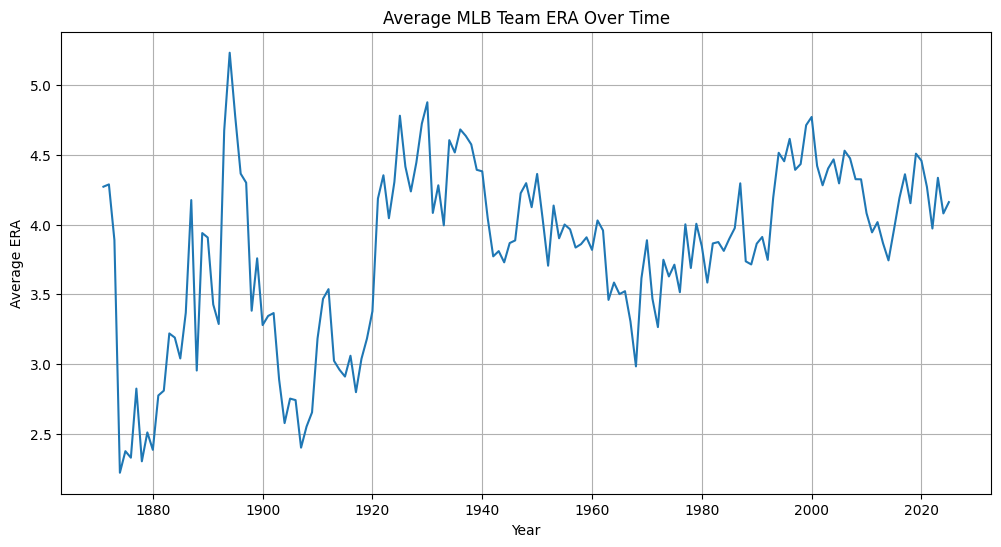

In [4]:
# Calculates average ERA by year and makes a line graph
era_by_year = team_pitching.groupby("yearID")["ERA"].mean()

era_by_year.plot(
    kind="line",
    figsize=(12, 6),
    title="Average MLB Team ERA Over Time",
    xlabel="Year",
    ylabel="Average ERA",
    grid=True
)